# Forex Currency Prediction
End-to-end notebook: **load → clean → explore → model → compare → save**.

> Put your Excel file in `data/` and set `DATA_FILE` below. A synthetic sample (`forex_sample.xlsx`) is included so the notebook runs out of the box. **Results on the sample are not real market results.**

In [2]:
   %pip install pandas numpy matplotlib seaborn openpyxl statsmodels prophet scikit-learn joblib streamlit plotly requests ipykernel

Note: you may need to restart the kernel to use updated packages.


## Step 1: Load and clean the data

In [3]:
import glob, os, warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

# 👉 Set to your own file, e.g. "data/Foreign_Exchange_Rates.xlsx". None = newest .xlsx in data/ (your file wins over the sample).
DATA_FILE = None
if DATA_FILE is None:
    files = sorted(glob.glob("data/*.xlsx"), key=lambda f: ("sample" in f, -os.path.getmtime(f)))
    DATA_FILE = files[0]
print("Using:", DATA_FILE)

df = pd.read_excel(DATA_FILE)
df.head()

Using: data\forex_data.xlsx


,Date,AUD,CAD,CHF,CNY,EUR,GBP,INR,JPY
0,2014-12-31,1.2214,1.1583,0.99036,6.2069,0.82366,0.64155,63.190,119.62
1,2015-01-02,1.2323,1.1682,0.99826,6.2077,0.83036,0.64768,63.356,120.58
2,2015-01-05,1.2384,1.1784,1.00850,6.2200,0.83928,0.65690,63.463,120.02
3,2015-01-06,1.2288,1.1763,1.00840,6.2130,0.83935,0.65822,63.572,118.93
4,2015-01-07,1.2391,1.1830,1.01520,6.2135,0.84524,0.66123,63.175,119.32


In [4]:
# First column is treated as the date column
DATE_COL = df.columns[0]
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df = df.dropna(subset=[DATE_COL]).drop_duplicates(subset=[DATE_COL])
df = df.sort_values(DATE_COL).set_index(DATE_COL)

# junk text such as "ND" becomes blank, then gaps are filled with the last known value
df = df.apply(pd.to_numeric, errors="coerce")
df = df.dropna(axis=1, how="all")
print("Missing values before fill:\n", df.isna().sum())
df = df.ffill().bfill()
currencies = list(df.columns)
print("\nCurrencies:", currencies)
df.describe().T

Missing values before fill:
 AUD    0
CAD    0
CHF    0
CNY    0
EUR    0
GBP    0
INR    0
JPY    0
dtype: int64

Currencies: ['AUD', 'CAD', 'CHF', 'CNY', 'EUR', 'GBP', 'INR', 'JPY']


,count,mean,std,min,25%,50%,75%,max
AUD,3027.0,1.415052,0.093866,1.20800,1.335950,1.40640,1.492050,1.72530
CAD,3027.0,1.326183,0.053024,1.15830,1.287400,1.32780,1.365500,1.46500
CHF,3027.0,0.928805,0.064223,0.76703,0.894030,0.93802,0.982295,1.03120
CNY,3027.0,6.797480,0.315240,6.19310,6.524450,6.82340,7.076450,7.34980
EUR,3027.0,0.892774,0.041317,0.80045,0.860145,0.89174,0.920220,1.04550
GBP,3027.0,0.759809,0.048488,0.62846,0.737665,0.76312,0.791145,0.94373
INR,3027.0,75.515060,9.026793,61.38400,67.365000,73.94600,83.080000,96.83000
JPY,3027.0,125.291417,18.971961,99.81000,109.590000,115.26000,144.910000,163.91000


## Explore the time series

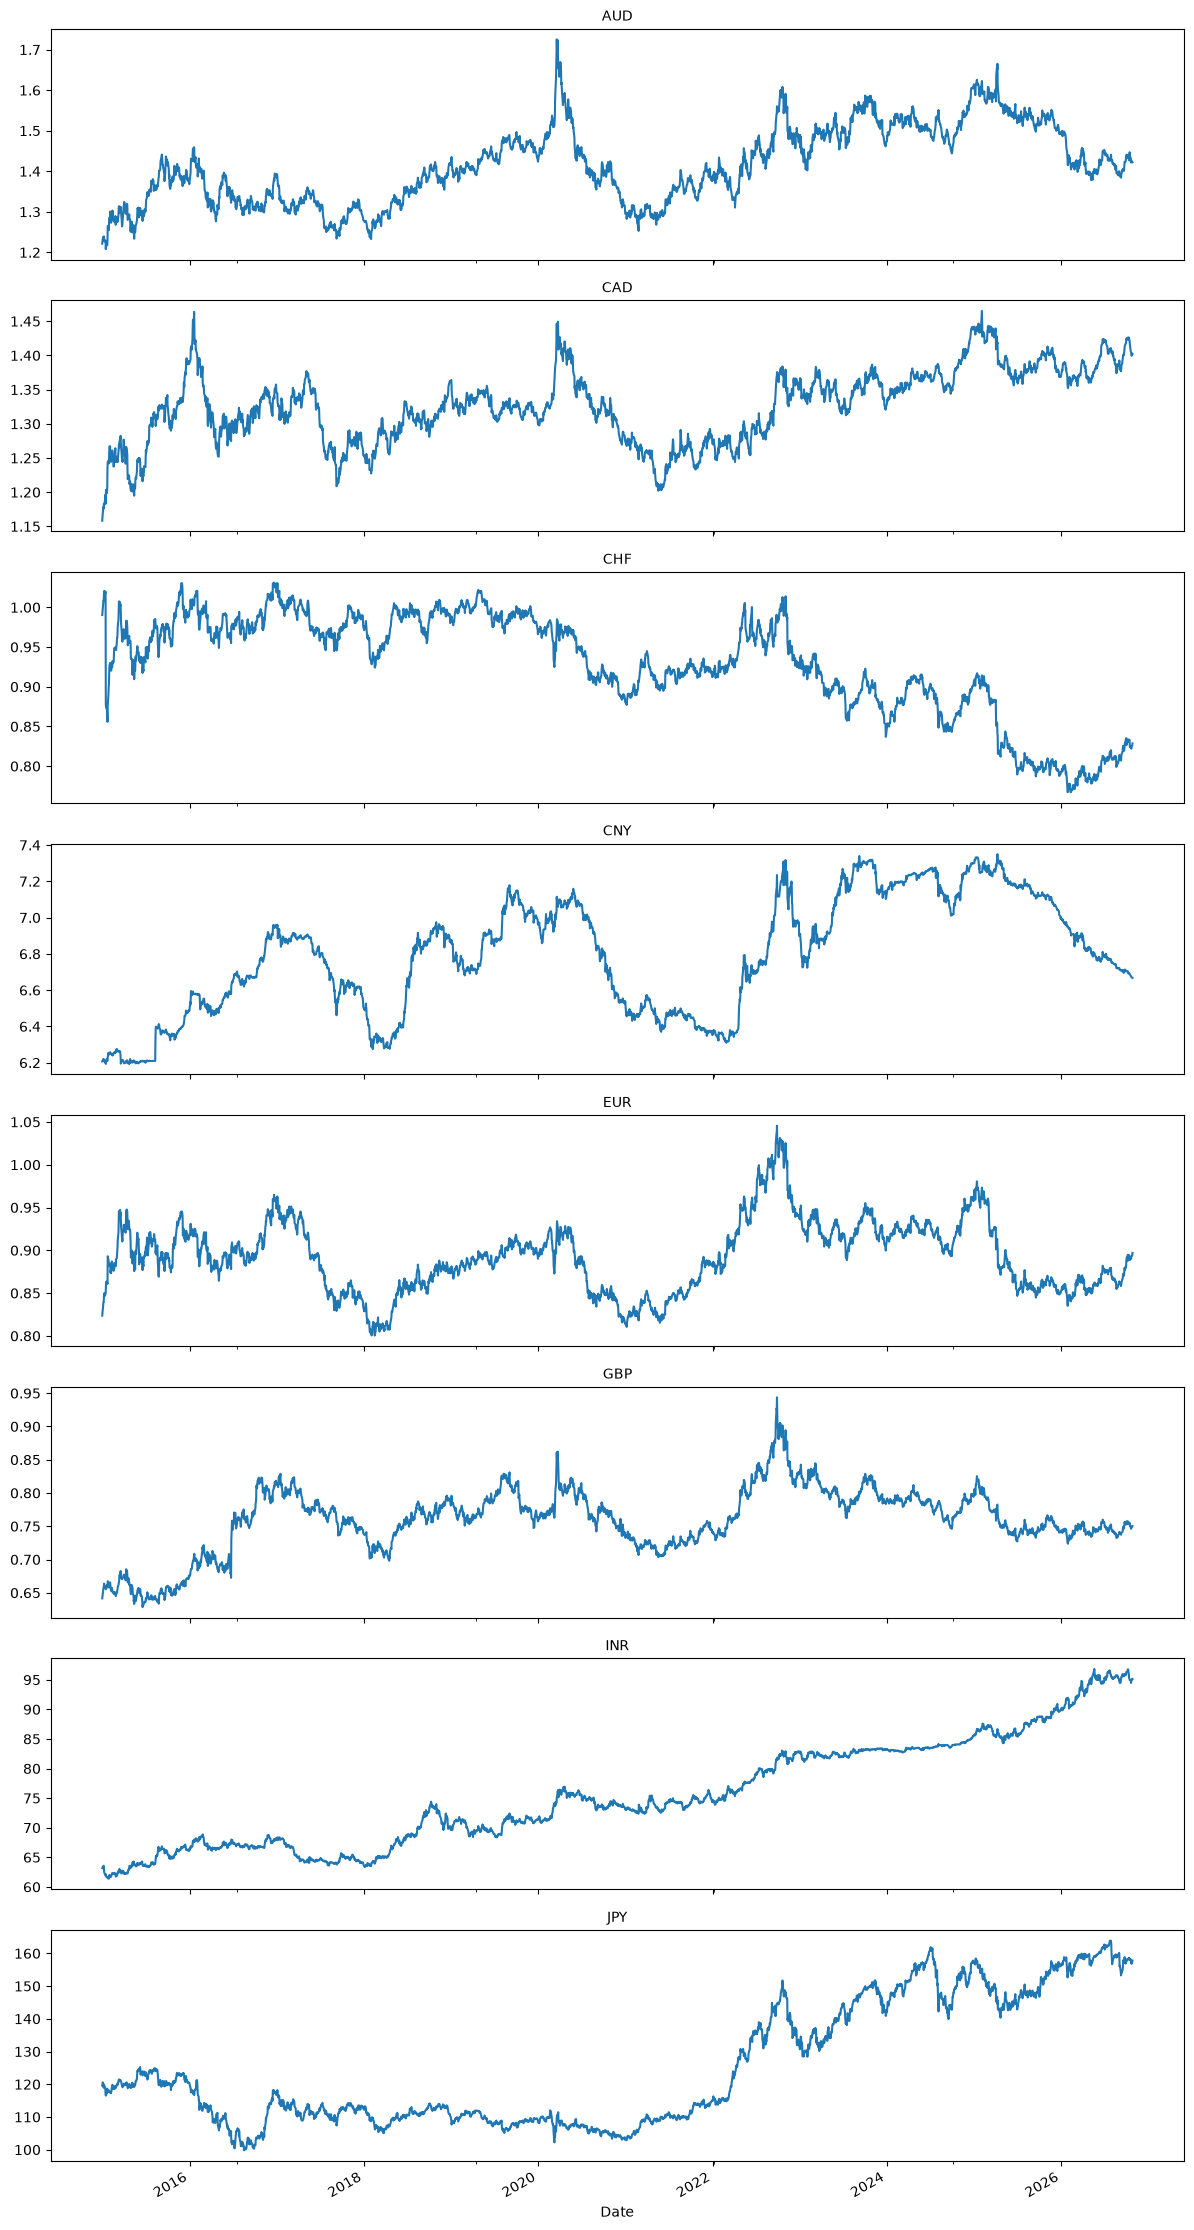

In [5]:
fig, axes = plt.subplots(len(currencies), 1, figsize=(12, 2.8*len(currencies)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), currencies):
    df[c].plot(ax=ax); ax.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

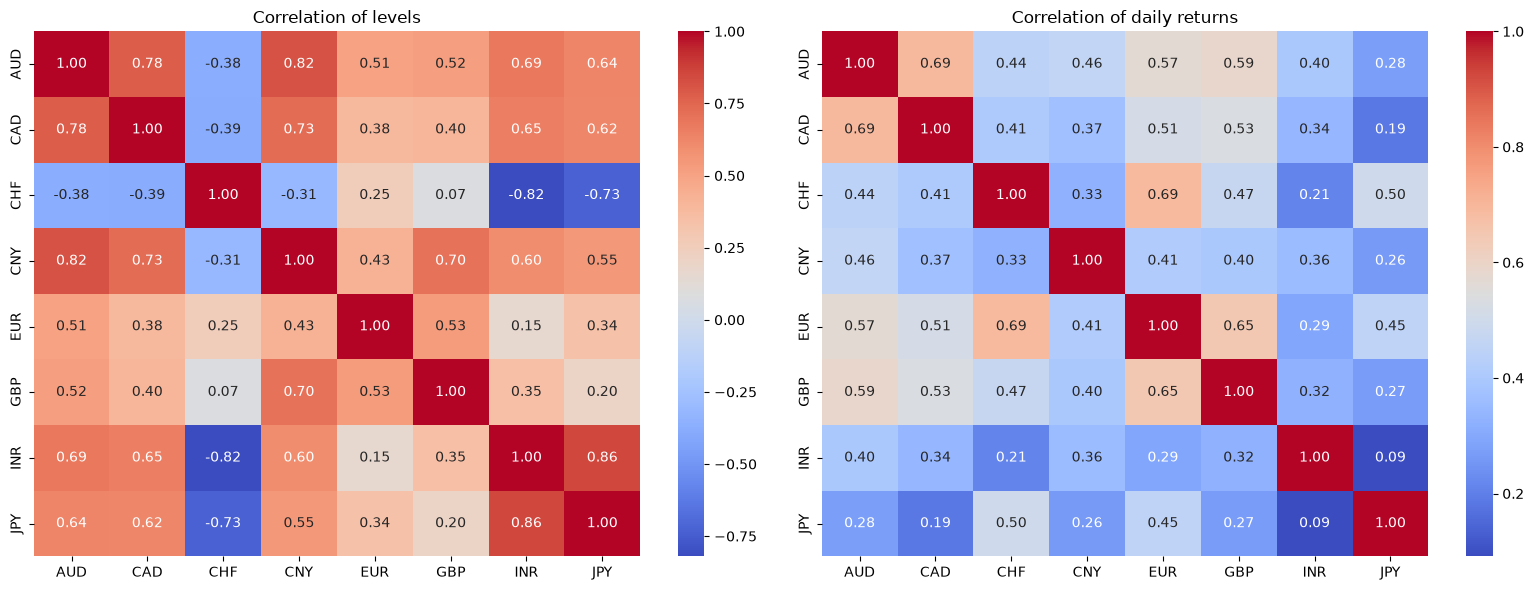

In [6]:
# Do currencies move together? (correlation of daily % changes is more honest than of raw levels)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[0]); ax[0].set_title("Correlation of levels")
sns.heatmap(df.pct_change().corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1]); ax[1].set_title("Correlation of daily returns")
plt.tight_layout(); plt.show()

In [7]:
# Volatility: how much each currency swings day to day
vol = (df.pct_change().std()*100).sort_values(ascending=False).rename("daily volatility (%)")
vol.round(3)

AUD    0.642
GBP    0.577
JPY    0.576
CHF    0.555
EUR    0.490
CAD    0.453
INR    0.309
CNY    0.244
Name: daily volatility (%), dtype: float64

**Insights to write in your report:** which currencies trend up/down, which are most volatile (table above), and which move together (heatmaps).

## Step 2: Train and compare models (last 60 days = test)
Models: **Naive** (repeat last value), **ARIMA**, **Prophet**. Metrics: MAE, RMSE, MAPE (lower is better). A separate model is trained per currency.

In [8]:
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

H = 60  # test days

def score(actual, pred):
    actual, pred = np.asarray(actual), np.asarray(pred)
    return (mean_absolute_error(actual, pred),
            float(np.sqrt(mean_squared_error(actual, pred))),
            float(np.mean(np.abs((actual - pred) / actual)) * 100))

def fit_prophet(s):
    m = Prophet(daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": s.index, "y": s.values}))
    return m

rows, test_preds = [], {}
for cur in currencies:
    s = df[cur]
    train, test = s.iloc[:-H], s.iloc[-H:]
    preds = {
        "Naive":   np.repeat(train.iloc[-1], H),
        "ARIMA":   np.asarray(ARIMA(train.values, order=(1, 1, 1)).fit().forecast(H)),
        "Prophet": fit_prophet(train).predict(pd.DataFrame({"ds": test.index}))["yhat"].values,
    }
    test_preds[cur] = (test, preds)
    for name, p in preds.items():
        rows.append([cur, name, *score(test.values, p)])

results = pd.DataFrame(rows, columns=["Currency", "Model", "MAE", "RMSE", "MAPE %"])
results.round(4)

20:57:08 - cmdstanpy - INFO - Chain [1] start processing
20:57:10 - cmdstanpy - INFO - Chain [1] done processing
20:57:10 - cmdstanpy - INFO - Chain [1] start processing
20:57:12 - cmdstanpy - INFO - Chain [1] done processing
c:\Users\akshi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
20:57:12 - cmdstanpy - INFO - Chain [1] start processing
20:57:13 - cmdstanpy - INFO - Chain [1] done processing
20:57:13 - cmdstanpy - INFO - Chain [1] start processing
20:57:16 - cmdstanpy - INFO - Chain [1] done processing
20:57:16 - cmdstanpy - INFO - Chain [1] start processing
20:57:18 - cmdstanpy - INFO - Chain [1] done processing
c:\Users\akshi\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retva

,Currency,Model,MAE,RMSE,MAPE %
0,AUD,Naive,0.0156,0.0189,1.1080
1,AUD,ARIMA,0.0156,0.0190,1.1114
2,AUD,Prophet,0.0489,0.0508,3.4732
3,CAD,Naive,0.0145,0.0165,1.0367
4,CAD,ARIMA,0.0145,0.0165,1.0364
5,CAD,Prophet,0.0108,0.0139,0.7649
6,CHF,Naive,0.0110,0.0139,1.3298
7,CHF,ARIMA,0.0110,0.0139,1.3295
8,CHF,Prophet,0.0574,0.0581,7.0027
9,CNY,Naive,0.0429,0.0478,0.6399


In [9]:
best = results.loc[results.groupby("Currency")["RMSE"].idxmin()].reset_index(drop=True)
print("Best model per currency (lowest RMSE):")
best.round(4)

Best model per currency (lowest RMSE):


,Currency,Model,MAE,RMSE,MAPE %
0,AUD,Naive,0.0156,0.0189,1.1080
1,CAD,Prophet,0.0108,0.0139,0.7649
2,CHF,ARIMA,0.0110,0.0139,1.3295
3,CNY,ARIMA,0.0428,0.0477,0.6394
4,EUR,ARIMA,0.0119,0.0147,1.3517
5,GBP,ARIMA,0.0068,0.0077,0.9061
6,INR,Naive,0.4435,0.5591,0.4636
7,JPY,ARIMA,1.2991,1.6177,0.8263


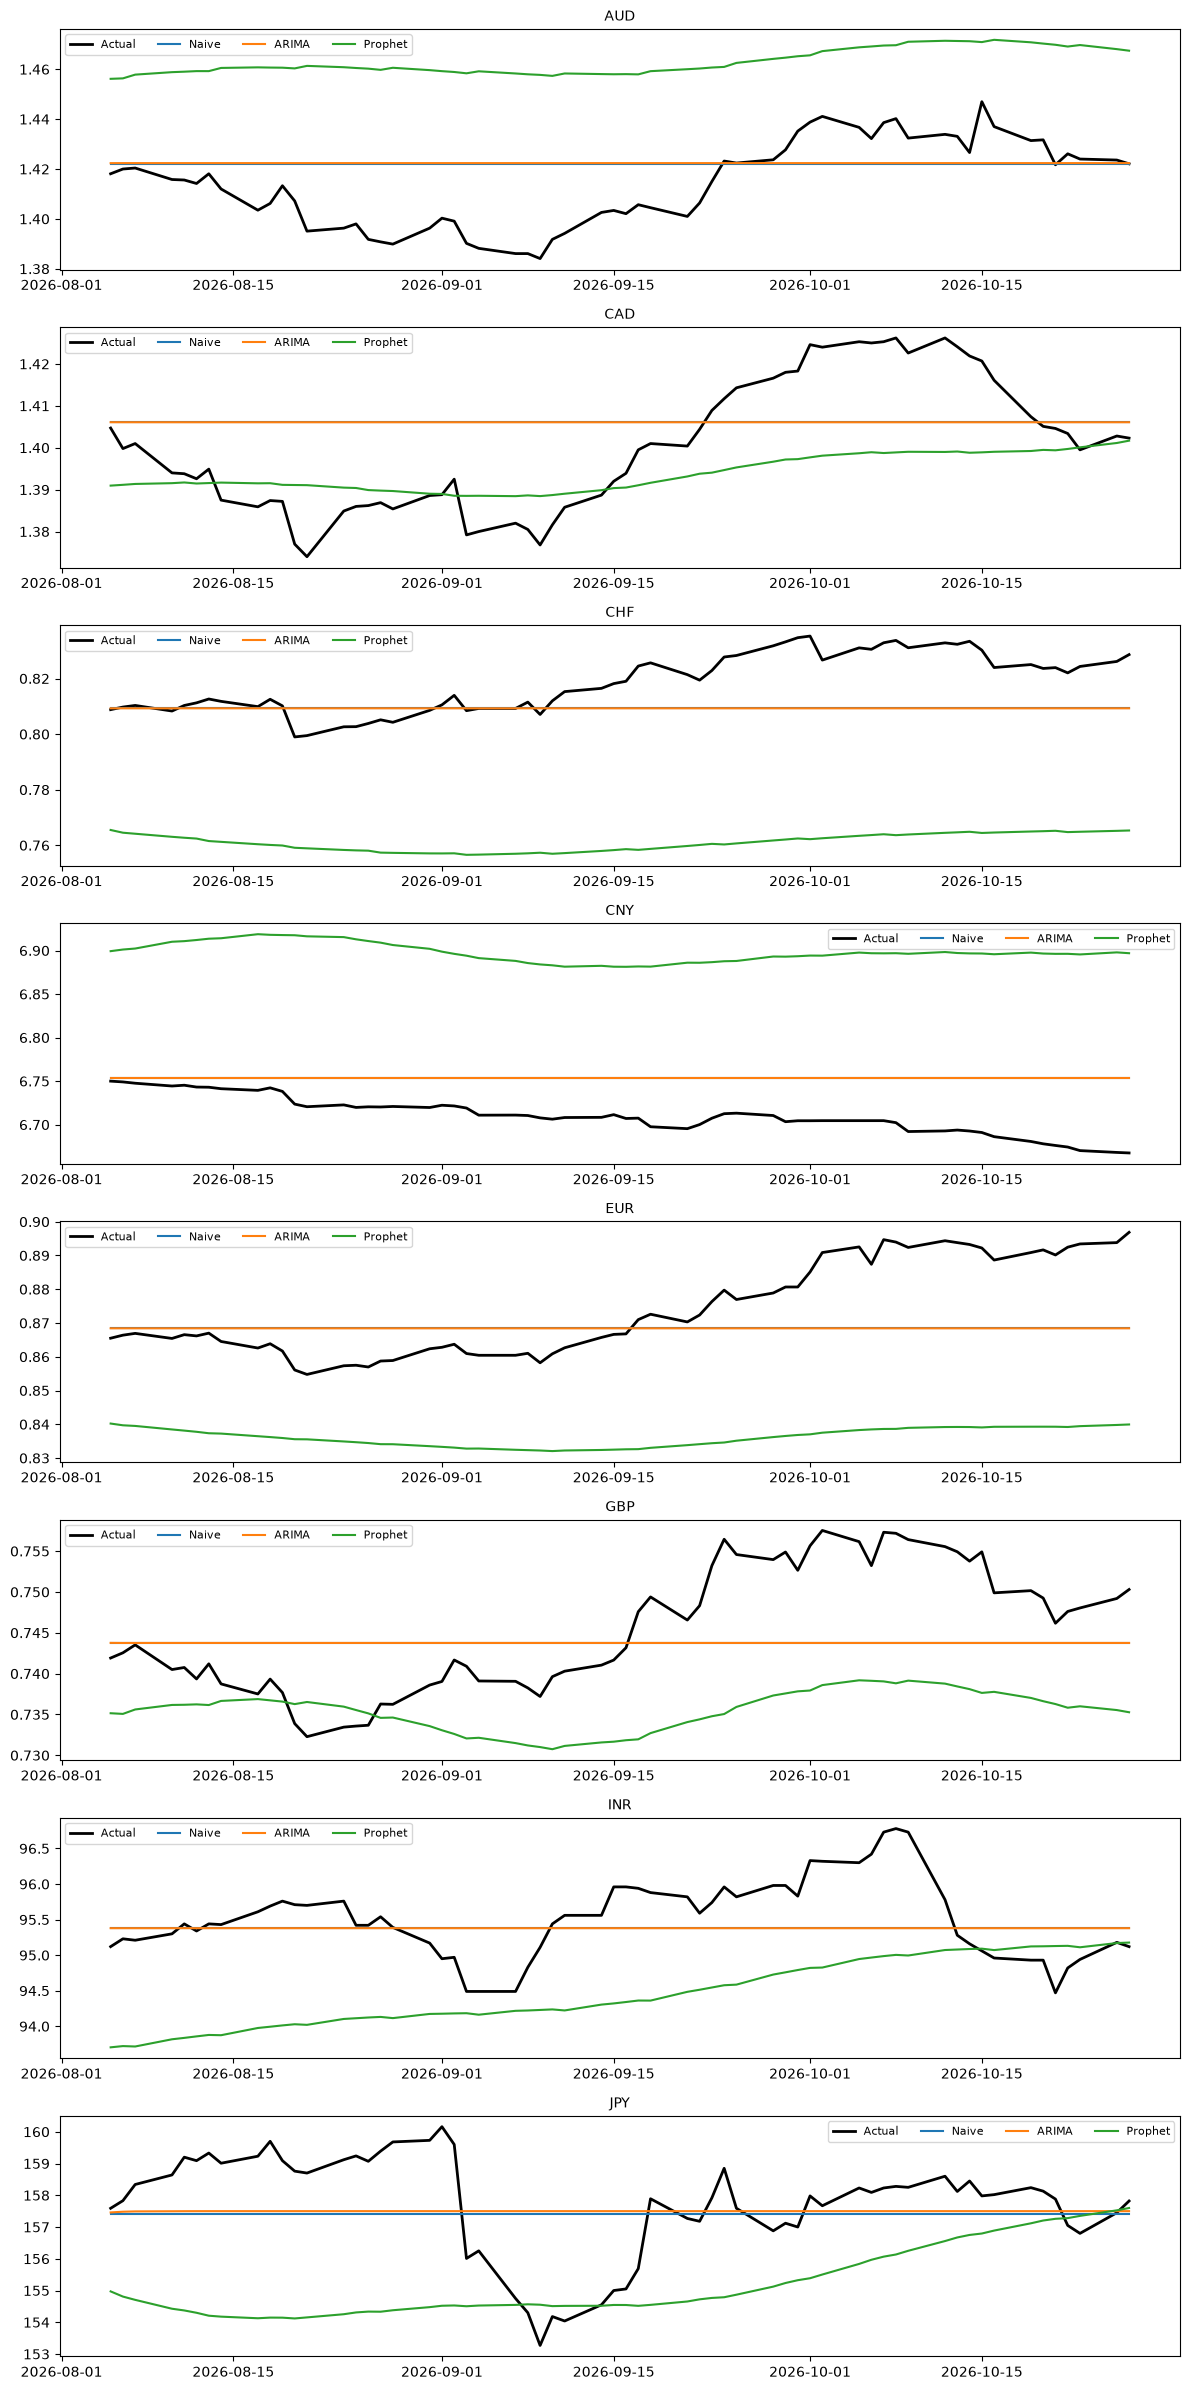

In [10]:
fig, axes = plt.subplots(len(currencies), 1, figsize=(12, 3*len(currencies)))
for ax, cur in zip(np.atleast_1d(axes), currencies):
    test, preds = test_preds[cur]
    ax.plot(test.index, test.values, "k", lw=2, label="Actual")
    for n, p in preds.items(): ax.plot(test.index, p, label=n)
    ax.set_title(cur, fontsize=10); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

> **Honest note:** exchange rates behave close to a random walk, so the Naive baseline often wins or ties. If it does, that is a legitimate finding.

## Step 3: Retrain each winner on ALL data and save it

In [11]:
import joblib
os.makedirs("models", exist_ok=True)
for f in glob.glob("models/*_model.pkl"): os.remove(f)   # clear old models

for _, r in best.iterrows():
    cur, name = r["Currency"], r["Model"]
    s = df[cur]
    if name == "ARIMA":
        model = ARIMA(s.values, order=(1, 1, 1)).fit()
    elif name == "Prophet":
        model = fit_prophet(s)
    else:
        model = None  # Naive needs no model
    safe = "".join(ch if ch.isalnum() else "_" for ch in cur).strip("_")
    joblib.dump({"type": name, "model": model, "currency": cur,
                 "last_date": s.index[-1], "last_value": float(s.iloc[-1]),
                 "rmse": float(r["RMSE"]), "history": s.iloc[-180:]},
                f"models/{safe}_model.pkl")
sorted(os.listdir("models"))

20:57:27 - cmdstanpy - INFO - Chain [1] start processing
20:57:29 - cmdstanpy - INFO - Chain [1] done processing


['AUD_model.pkl',
 'CAD_model.pkl',
 'CHF_model.pkl',
 'CNY_model.pkl',
 'EUR_model.pkl',
 'GBP_model.pkl',
 'INR_model.pkl',
 'JPY_model.pkl']

In [12]:
results.to_csv("model_comparison.csv", index=False)
best.to_csv("best_models.csv", index=False)
print("Saved model_comparison.csv and best_models.csv")

Saved model_comparison.csv and best_models.csv
